In [ ]:
# uncomment if you haven't installed yet
# ! pip install git+https://github.com/galuszkm/pyRPC3.git

In [ ]:
def graph_rcp(rcp_path):
    # weird fuckery that depends on if you have matplot idk this might break if you ahve a different setup
    %matplotlib inline
    import matplotlib.pyplot as plt
    from pyRPC3 import RPC3
    import numpy as np

    plt.close("all")

    rpc = RPC3(rcp_path, debug=False)

    # Create a 4x3 grid
    fig, axes = plt.subplots(4, 3, figsize=(15, 12))
    axes = axes.flatten()  # Flatten to 1D array for easier indexing

    # Plot each channel
    for idx, channel in enumerate(rpc.channels):
        ax = axes[idx]
        # divide x axis by 500 to convert to seconds
        time_axis = np.arange(len(channel.values)) / 500
        ax.plot(time_axis, channel.values)
        
        # Calculate statistics
        mean_val = np.mean(channel.values)
        min_val = np.min(channel.values)
        max_val = np.max(channel.values)
        std_val = np.std(channel.values)
        
        ax.set_title(f"Channel {channel.number}: {channel.name}")
        ax.set_ylabel(channel.units)
        ax.set_xlabel("seconds")
        ax.grid(True, alpha=0.3)
        
        # Add statistics as text box in lower-left corner
        stats_text = f"Mean: {mean_val:.3f}\nMin: {min_val:.3f}\nMax: {max_val:.3f}\nStd: {std_val:.3f}"
        ax.text(0.02, 0.02, stats_text, transform=ax.transAxes, 
                fontsize=8, verticalalignment='bottom', horizontalalignment='left',
                bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.7))

    # Hide the empty subplot (12th one)
    if len(rpc.channels) < len(axes):
        axes[-1].set_visible(False)

    plt.tight_layout()
    plt.show()

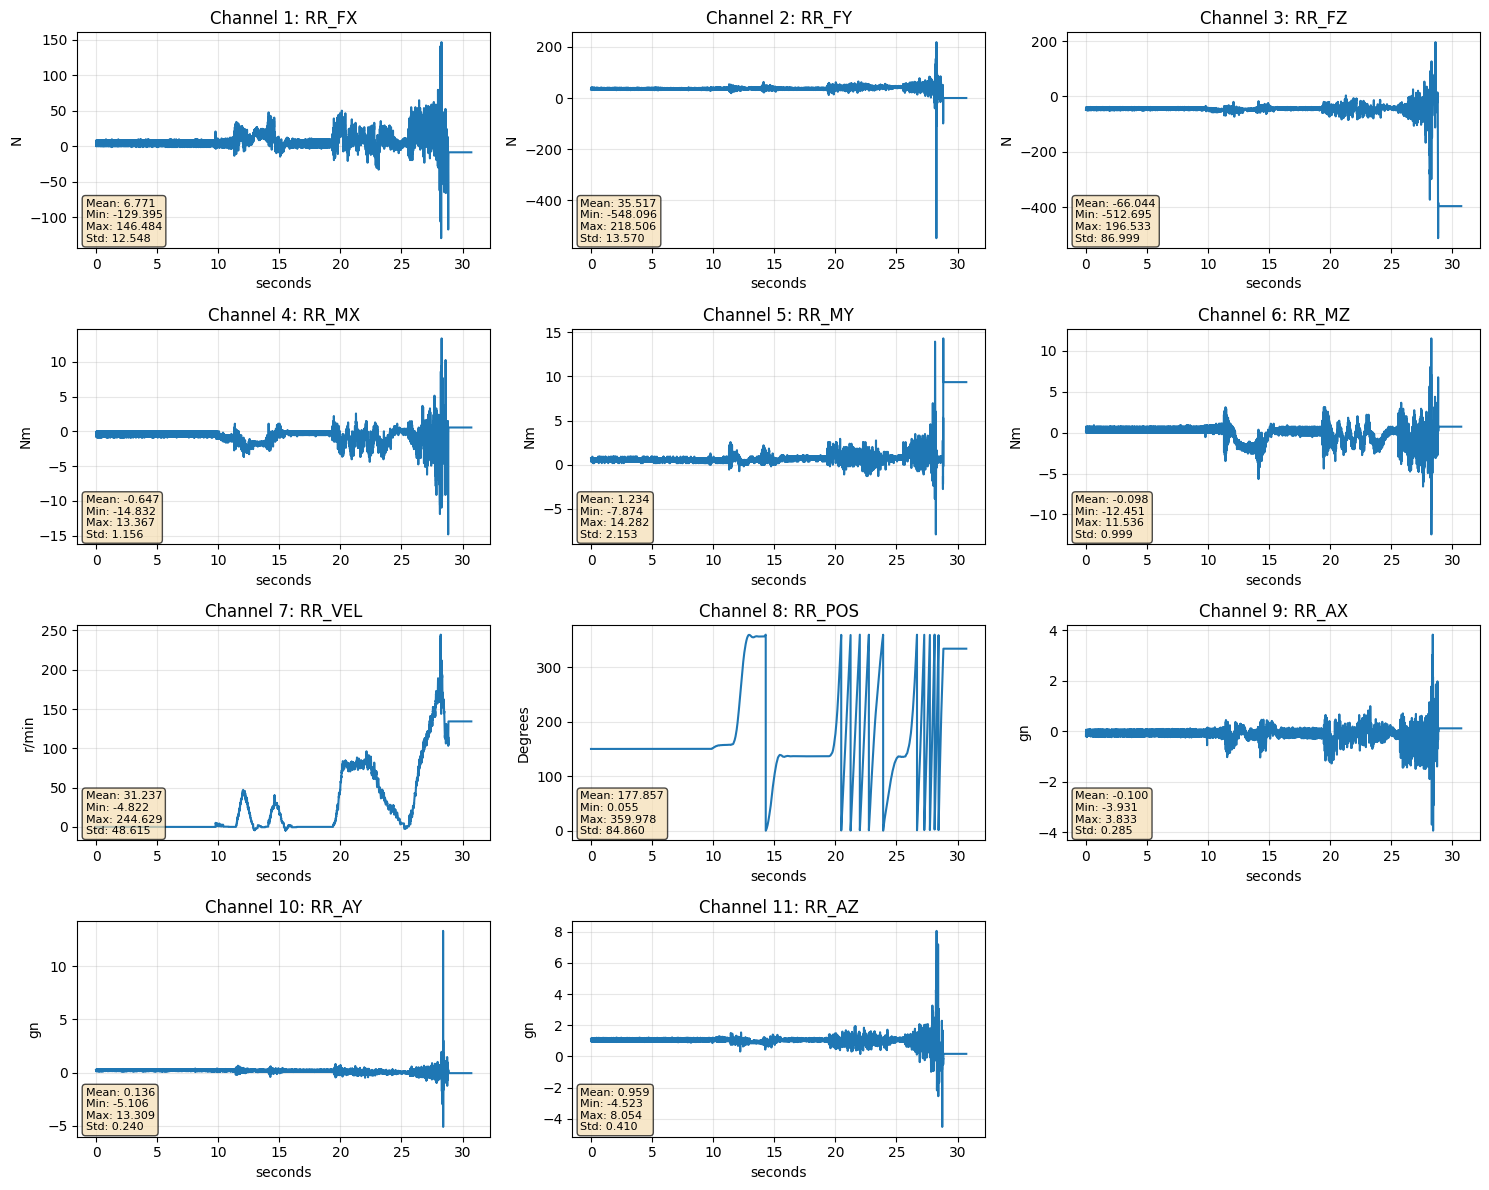

In [ ]:
# change this to the file you want to graph
# thats it
graph_rcp("CT3data med 3.rsp")

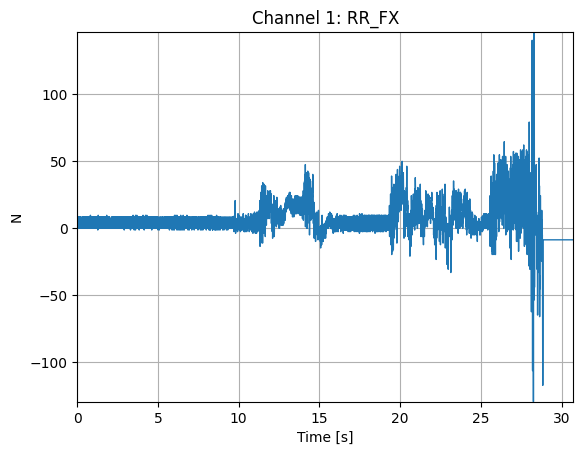


Channel No      Name                           Units           Min             Max            
------------------------------------------------------------------------------------------
1               RR_FX                          N               -1.294e+02      1.465e+02      
2               RR_FY                          N               -5.481e+02      2.185e+02      
3               RR_FZ                          N               -5.127e+02      1.965e+02      
4               RR_MX                          Nm              -1.483e+01      1.337e+01      
5               RR_MY                          Nm              -7.874e+00      1.428e+01      
6               RR_MZ                          Nm              -1.245e+01      1.154e+01      
7               RR_VEL                         r/min           -4.822e+00      2.446e+02      
8               RR_POS                         Degrees         5.493e-02       3.600e+02      
9               RR_AX                          gn    

In [66]:
import matplotlib.pyplot as plt
from pyRPC3 import RPC3

rpc = RPC3("CT3data med 3.rsp")
# Plot the first channel (ensure interactive backend is set as described above)
rpc.channels[0].plot()
plt.show()
rpc.info()